In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import random
import time

In [2]:
def set_seed(seed=123):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.config.experimental.enable_op_determinism()

set_seed(123)


### Целевая функция:

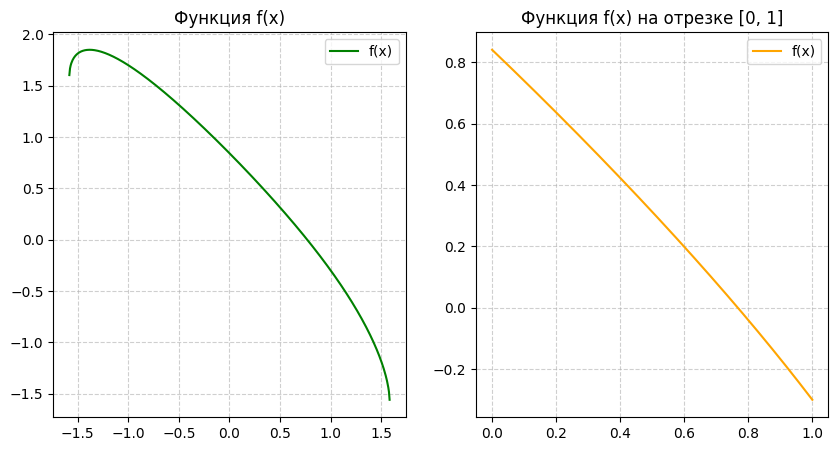

In [3]:
func = lambda x: np.sin(np.sqrt(1 - 0.4*x**2)) - x
a = 0
b = 1

x_full_func = np.linspace(-1.6, 1.6, 500)
valid_mask = ((1 - 0.4*x_full_func**2) >= 0)
x_valid = x_full_func[valid_mask]
x = np.linspace(a, b, 1000)
    
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].plot(x_valid, func(x_valid), c='green', label='f(x)')
axes[0].set_title("Функция f(x)")
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

axes[1].plot(x, func(x), c='orange', label='f(x)')
axes[1].set_title("Функция f(x) на отрезке [0, 1]")
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()
plt.savefig('func.png', dpi=300)
plt.show()

### Реализация моделей:

In [4]:
# Shallow MLP (Малая полносвязная сеть)
def shallowMLP():
    model = models.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation='relu'),
        layers.Dense(1)
    ])
    model.compile(
        optimizer='adam',
        loss='mse')
    return model


# Deep MLP (Глубокий персептрон)
def deepMLP():
    model = models.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(1)
    ])
    model.compile(
        optimizer='adam',
        loss='mse')
    return model

# 1D CNN (Сверточная сеть)
def conv1Dnet():
    model = models.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(32, activation='relu'),
        layers.Reshape((32, 1)),
        layers.Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'),
        layers.Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'),
        layers.Flatten(),
        layers.Dense(1)
    ])
    model.compile(
        optimizer='adam',
        loss='mse')
    return model

# ResNet-MLP (Сеть с остаточными связями)
def resnetMLP():
    inputs = layers.Input(shape=(1,))
    x = layers.Dense(64, activation='relu')(inputs)
    for _ in range(2):
        residual = x
        x = layers.Dense(64, activation='relu')(x)
        x = layers.Dense(64)(x)
        x = layers.Add()([x, residual])
        x = layers.Activation('relu')(x)
    outputs = layers.Dense(1)(x)
    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='mse')
    return model

    


### Обучающая и тестовая выборки:

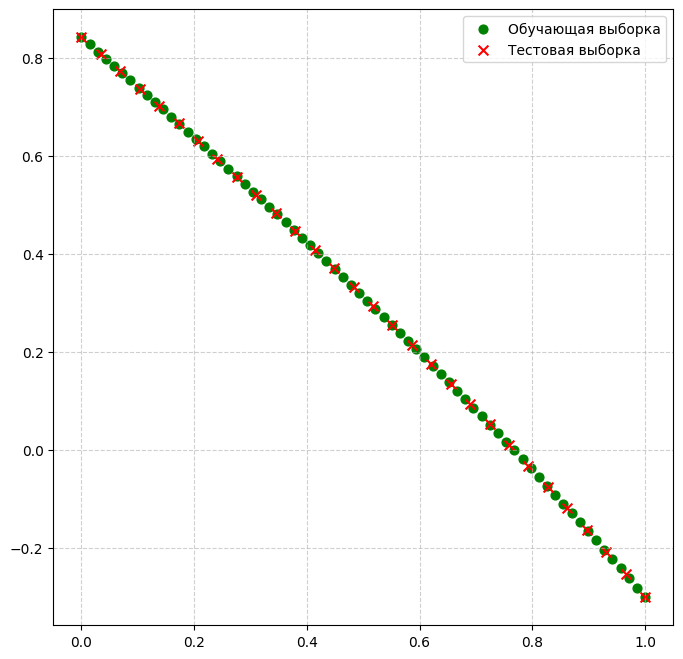

In [5]:
N_TRAIN = 70
N_TEST = 30

x_train = np.linspace(a, b, N_TRAIN).reshape(-1, 1)
y_train = func(x_train).reshape(-1, 1)
x_test = np.linspace(a, b, N_TEST).reshape(-1, 1)
y_test = func(x_test).reshape(-1, 1)

plt.figure(figsize=(8, 8))
plt.scatter(x_train, y_train, s=40, marker='o', c='green', label='Обучающая выборка')
plt.scatter(x_test, y_test, s=50, marker='x', c='red', label='Тестовая выборка')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('samples.png', dpi = 300)
plt.show()


### Обучение и настройка моделей:

In [6]:
epochs = 30
batch_size = 32
verbose = 0

In [7]:
model_shallow = shallowMLP()
history_shallow = model_shallow.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose)
y_pred_shallow = model_shallow.predict(x_test)

mse_shallow = mean_squared_error(y_test, y_pred_shallow)
mae_shallow = mean_absolute_error(y_test, y_pred_shallow)
r2_shallow = r2_score(y_test, y_pred_shallow)

print("shallowMLP:")
print("mse: ", mse_shallow)
print("mae: ", mae_shallow)
print("r2: ", r2_shallow)

2026-11-10 13:59:28.051270: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
shallowMLP:
mse:  0.12337552553676683
mae:  0.30237725698954393
r2:  -0.07371744909119493


In [8]:
model_deep = deepMLP()
history_deep = model_deep.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose)
y_pred_deep = model_deep.predict(x_test)

mse_deep = mean_squared_error(y_test, y_pred_deep)
mae_deep = mean_absolute_error(y_test, y_pred_deep)
r2_deep = r2_score(y_test, y_pred_deep)

print("deepMLP:")
print("mse: ", mse_deep)
print("mae: ", mae_deep)
print("r2: ", r2_deep)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
deepMLP:
mse:  0.0005916879663808743
mae:  0.014747898863095755
r2:  0.9948506343445637


In [9]:
model_conv = conv1Dnet()
history_conv = model_conv.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose)
y_pred_conv = model_conv.predict(x_test)

mse_conv = mean_squared_error(y_test, y_pred_conv)
mae_conv = mean_absolute_error(y_test, y_pred_conv)
r2_conv = r2_score(y_test, y_pred_conv)

print("convMLP:")
print("mse: ", mse_conv)
print("mae: ", mae_conv)
print("r2: ", r2_conv)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
convMLP:
mse:  0.000516511169794047
mae:  0.015614353320921105
r2:  0.9955048859711394


In [10]:
model_resnet = resnetMLP()
history_resnet = model_resnet.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose)
y_pred_resnet = model_resnet.predict(x_test)

mse_resnet = mean_squared_error(y_test, y_pred_resnet)
mae_resnet = mean_absolute_error(y_test, y_pred_resnet)
r2_resnet = r2_score(y_test, y_pred_resnet)

print("resnetMLP:")
print("mse: ", mse_resnet)
print("mae: ", mae_resnet)
print("r2: ", r2_resnet)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
resnetMLP:
mse:  0.00016425625488779465
mae:  0.00963367706279947
r2:  0.998570504107455


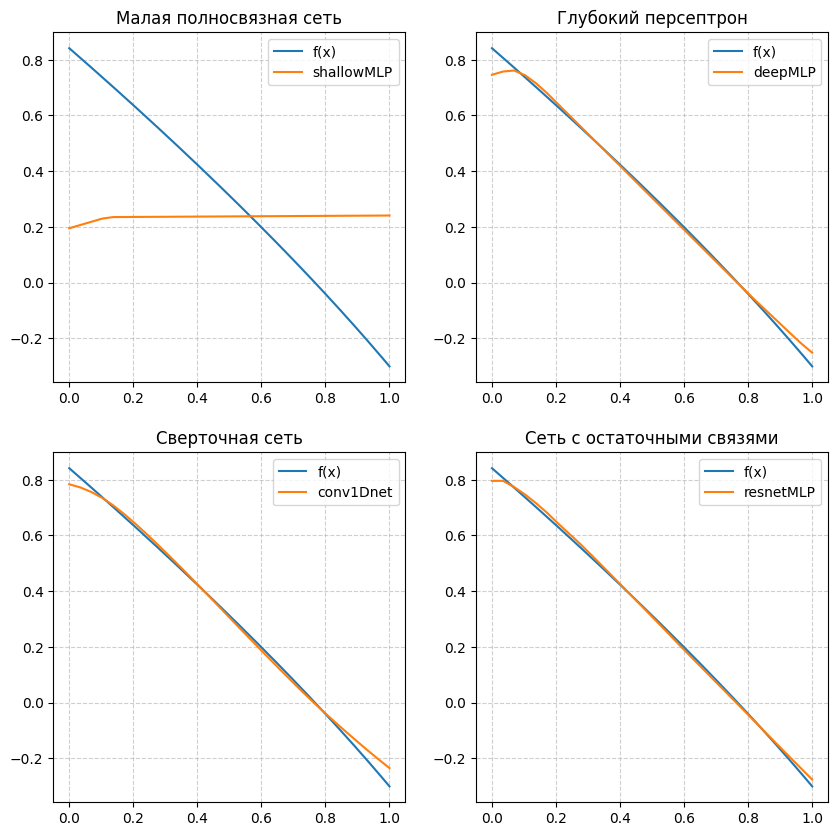

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()

axes[0].plot(x, func(x), label='f(x)')
axes[0].plot(x_test, y_pred_shallow, label='shallowMLP')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].set_title('Малая полносвязная сеть')
axes[0].legend()

axes[1].plot(x, func(x), label='f(x)')
axes[1].plot(x_test, y_pred_deep, label='deepMLP')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].set_title('Глубокий персептрон')
axes[1].legend()

axes[2].plot(x, func(x), label='f(x)')
axes[2].plot(x_test, y_pred_conv, label='conv1Dnet')
axes[2].grid(True, linestyle='--', alpha=0.6)
axes[2].set_title('Сверточная сеть')
axes[2].legend()

axes[3].plot(x, func(x), label='f(x)')
axes[3].plot(x_test, y_pred_resnet, label='resnetMLP')
axes[3].grid(True, linestyle='--', alpha=0.6)
axes[3].set_title('Сеть с остаточными связями')
axes[3].legend()

plt.savefig('graf.png', dpi = 300)
plt.show()

### Экстраполяция сверточной нейронной сети:

In [12]:
x_left = np.linspace(a-1.5, a, 50).reshape(-1, 1)
y_left = func(x_left).reshape(-1, 1)
x_right = np.linspace(b, b+0.5, 50).reshape(-1, 1)
y_right = func(x_right).reshape(-1, 1)

y_conv_left = model_conv.predict(x_left)
y_conv_right = model_conv.predict(x_right)

mse_conv_left = mean_squared_error(y_left, y_conv_left)
mae_conv_left = mean_absolute_error(y_left, y_conv_left)
r2_conv_left = r2_score(y_left, y_conv_left)

mse_conv_right = mean_squared_error(y_right, y_conv_right)
mae_conv_right = mean_absolute_error(y_right, y_conv_right)
r2_conv_right = r2_score(y_right, y_conv_right)

print("convMLP left:")
print("mse: ", mse_conv_left)
print("mae: ", mae_conv_left)
print("r2: ", r2_conv_left)

print("convMLP right:")
print("mse: ", mse_conv_right)
print("mae: ", mae_conv_right)
print("r2: ", r2_conv_right)



2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
convMLP left:
mse:  1.1889696161303775
mae:  0.9702359039299879
r2:  -10.640077457027388
convMLP right:
mse:  0.10634217229806256
mae:  0.283763101366309
r2:  -0.6267064363371366


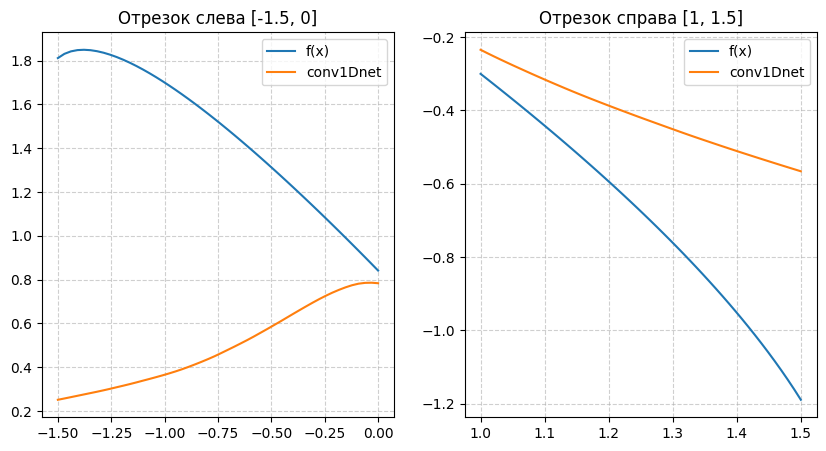

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes = axes.flatten()

axes[0].plot(x_left, y_left, label='f(x)')
axes[0].plot(x_left, y_conv_left, label='conv1Dnet')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].set_title('Отрезок слева [-1.5, 0]')
axes[0].legend()

axes[1].plot(x_right, y_right, label='f(x)')
axes[1].plot(x_right, y_conv_right, label='conv1Dnet')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].set_title('Отрезок справа [1, 1.5]')
axes[1].legend()

plt.savefig('left_right.png', dpi = 300)
plt.show()

# Исследование влияния параметров на качество обучения модели

In [14]:
# Базовая функция для сборки Deep MLP с настраиваемой активацией
def deepMLP_custom(activation_fn='relu'):
    model = models.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(64, activation=activation_fn),
        layers.Dense(64, activation=activation_fn),
        layers.Dense(64, activation=activation_fn),
        layers.Dense(1)
    ])
    return model

def run_experiment(param_name, 
                   param_values, 
                   base_optimizer='adam', 
                   base_activation='relu', 
                   base_epochs=30, 
                   base_batch=32):
    results = []
    
    for val in param_values:
        set_seed(123)
        
        # Настраиваем текущие параметры
        opt = val if param_name == 'optimizer' else base_optimizer
        act = val if param_name == 'activation' else base_activation
        ep  = val if param_name == 'epochs' else base_epochs
        bs  = val if param_name == 'batch_size' else base_batch
        
        # Сборка и компиляция модели
        model = deepMLP_custom(activation_fn=act)
        model.compile(optimizer=opt, loss='mse')
        
        start_time = time.perf_counter()
        history = model.fit(x_train, y_train, epochs=ep, batch_size=bs, verbose=0)
        train_time = time.perf_counter() - start_time
        
        start_pred = time.perf_counter()
        y_pred = model.predict(x_test, verbose=0)
        
        mse = mean_squared_error(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        r2  = r2_score(y_test, y_pred)
        
        results.append({
            'Параметр': param_name,
            'Значение': val,
            'Время обучения (с)': round(train_time, 4),
            'MSE': round(mse, 6),
            'MAE': round(mae, 6),
            'R2 Score': round(r2, 5)
        })
        
    return pd.DataFrame(results)


In [15]:
# 1. Исследование оптимизаторов
df_opt = run_experiment('optimizer', ['sgd', 'rmsprop', 'adam'])

# 2. Исследование функций активации
df_act = run_experiment('activation', ['relu', 'tanh', 'sigmoid', 'elu'])

# 3. Исследование количества эпох
df_ep  = run_experiment('epochs', [10, 30, 100, 300])

# 4. Исследование размера батча
df_bs  = run_experiment('batch_size', [8, 16, 32, 64, len(x_train)])

# Вывод сводных таблиц
print("--- Влияние оптимизаторов ---")
print(df_opt.to_string(index=False))

print("\n--- Влияние функций активации ---")
print(df_act.to_string(index=False))

print("\n--- Влияние количества эпох ---")
print(df_ep.to_string(index=False))

print("\n--- Влияние размера батча ---")
print(df_bs.to_string(index=False))


2026-11-10 13:59:33.534434: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-11-10 13:59:39.281864: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

--- Влияние оптимизаторов ---
 Параметр Значение  Время обучения (с)      MSE      MAE  R2 Score
optimizer      sgd              0.2801 0.079848 0.243076   0.30510
optimizer  rmsprop              0.4193 0.002174 0.043825   0.98108
optimizer     adam              0.5542 0.000492 0.015031   0.99571

--- Влияние функций активации ---
  Параметр Значение  Время обучения (с)      MSE      MAE  R2 Score
activation     relu              0.5515 0.000492 0.015031   0.99571
activation     tanh              0.5411 0.000292 0.013515   0.99746
activation  sigmoid              0.5551 0.114208 0.290667   0.00607
activation      elu              0.5478 0.000369 0.015754   0.99679

--- Влияние количества эпох ---
Параметр  Значение  Время обучения (с)      MSE      MAE  R2 Score
  epochs        10              0.4989 0.101386 0.272002   0.11765
  epochs        30              0.5611 0.000492 0.015031   0.99571
  epochs       100              1.0205 0.000109 0.008534   0.99905
  epochs       300        